# Huấn luyện mô hình Logistic Regression dự đoán mưa  Hà Nội

## 0. Kết nối Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Import thư viện và đọc dữ liệu

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, log_loss

DATA_DIR = '/content/drive/MyDrive'
df_train = pd.read_csv(f'{DATA_DIR}/train_data_weather.csv')
df_test = pd.read_csv(f'{DATA_DIR}/test_data_weather.csv')

print('Kích thước tập Train:', df_train.shape)
print('Kích thước tập Test:', df_test.shape)
df_train.head(3)

Kích thước tập Train: (3214, 10)
Kích thước tập Test: (804, 10)


,temperature,humidity,pressure,wind_speed,cloud_cover,season_autumn,season_spring,season_summer,season_winter,is_rain
0,-1.161489,1.10901,0.782674,-1.159387,0.964810,0,0,0,1,1
1,0.733653,1.10901,-1.125282,-1.063733,0.817414,1,0,0,0,1
2,0.632847,1.10901,-0.475471,-1.374608,0.117288,1,0,0,0,1


## 2. Huấn luyện và đánh giá mô hình

In [3]:
LABELS = ['Không mưa (0)', 'Có mưa (1)']

TARGET = df_train.columns[-1]          # cột cuối của file là nhãn
X_train, y_train = df_train.drop(columns=TARGET), df_train[TARGET]
X_test, y_test = df_test.drop(columns=TARGET), df_test[TARGET]

model = LogisticRegression(max_iter=1000).fit(X_train, y_train)

y_pred = model.predict(X_test)         # nhãn cứng (0 hoặc 1)
y_prob = model.predict_proba(X_test)   # xác suất từng lớp (để tính Log Loss)

print('Nhãn dự đoán:', TARGET)
print('Độ chính xác (Accuracy):', round(accuracy_score(y_test, y_pred), 4))
print('Sai số Log Loss:', round(log_loss(y_test, y_prob), 4))
print('\nBáo cáo phân loại chi tiết:\n', classification_report(y_test, y_pred, target_names=LABELS))

Nhãn dự đoán: is_rain
Độ chính xác (Accuracy): 0.8582
Sai số Log Loss: 0.3201

Báo cáo phân loại chi tiết:
                precision    recall  f1-score   support

Không mưa (0)       0.80      0.70      0.75       242
   Có mưa (1)       0.88      0.93      0.90       562

     accuracy                           0.86       804
    macro avg       0.84      0.81      0.83       804
 weighted avg       0.86      0.86      0.86       804



## 3. Ma trận nhầm lẫn (Confusion Matrix)

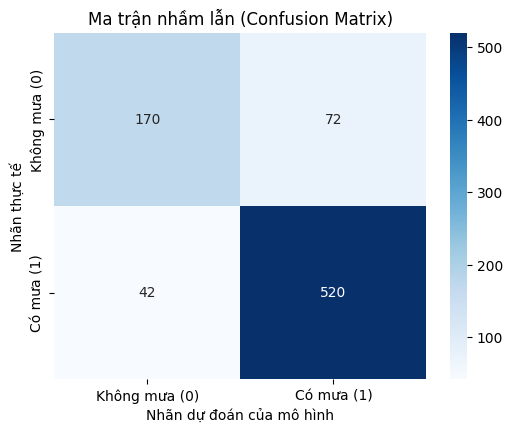

In [4]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS)
plt.title('Ma trận nhầm lẫn (Confusion Matrix)')
plt.xlabel('Nhãn dự đoán của mô hình')
plt.ylabel('Nhãn thực tế')
plt.show()